In [ ]:
# --- CELL 1: GRAPH TOPOLOGY ENVIRONMENT ---
!pip install -q networkx scipy scikit-image matplotlib numpy sknw

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import sknw
from scipy.spatial import distance
import math

print("Phase 2 Environment Initialized. Deep Learning dependencies excluded.")

# --- THE PHYSICAL ANCHOR ---
GSD_METERS_PER_PIXEL = 0.3077

# Pruning Thresholds (Physical Reality)
MIN_ROAD_LENGTH_METERS = 15.0  # Anything shorter leading to a dead end is a skeleton artifact
CLUSTER_RADIUS_METERS = 10.0   # Intersections closer than this are the same physical intersection

# Convert to Pixel Space for Algorithm Use
MIN_EDGE_PIXELS = MIN_ROAD_LENGTH_METERS / GSD_METERS_PER_PIXEL
CLUSTER_RADIUS_PIXELS = CLUSTER_RADIUS_METERS / GSD_METERS_PER_PIXEL

print(f"Operational GSD: {GSD_METERS_PER_PIXEL:.4f} m/px")
print(f"Spur Pruning Threshold: {MIN_EDGE_PIXELS:.1f} pixels ({MIN_ROAD_LENGTH_METERS}m)")
print(f"Intersection Collapse Radius: {CLUSTER_RADIUS_PIXELS:.1f} pixels ({CLUSTER_RADIUS_METERS}m)")

Phase 2 Environment Initialized. Deep Learning dependencies excluded.
Operational GSD: 0.3077 m/px
Spur Pruning Threshold: 48.7 pixels (15.0m)
Intersection Collapse Radius: 32.5 pixels (10.0m)


In [ ]:
# --- CELL 2: LOAD TENSOR ARTIFACTS ---
import os
import numpy as np
from google.colab import drive

# 1. Re-mount Drive in this isolated Phase 2 instance
print("Mounting Google Drive for Phase 2...")
drive.mount('/content/drive')

# 2. Point to the exact absolute paths in your persistent storage
SKELETON_PATH = "/content/drive/MyDrive/ISRO DATA/skeleton.npy"
COST_MAP_PATH = "/content/drive/MyDrive/ISRO DATA/cost_map.npy"

if not os.path.exists(SKELETON_PATH) or not os.path.exists(COST_MAP_PATH):
    raise FileNotFoundError(f"CRITICAL: Arrays not found. I looked exactly here:\n{SKELETON_PATH}\n{COST_MAP_PATH}\nIf they aren't there, your Phase 1 export failed.")

# 3. Load the arrays into CPU RAM
print("Loading topology arrays...")
skeleton_array = np.load(SKELETON_PATH).astype(np.uint8)
cost_map = np.load(COST_MAP_PATH)

print(f"Skeleton Shape Loaded: {skeleton_array.shape}")
print(f"Cost Map Shape Loaded: {cost_map.shape}")

Mounting Google Drive for Phase 2...
Mounted at /content/drive
Loading topology arrays...
Skeleton Shape Loaded: (1300, 1300)
Cost Map Shape Loaded: (1300, 1300)


Executing sknw pixel translation...
Raw Graph Instantiated:
 -> Nodes: 62
 -> Edges: 52


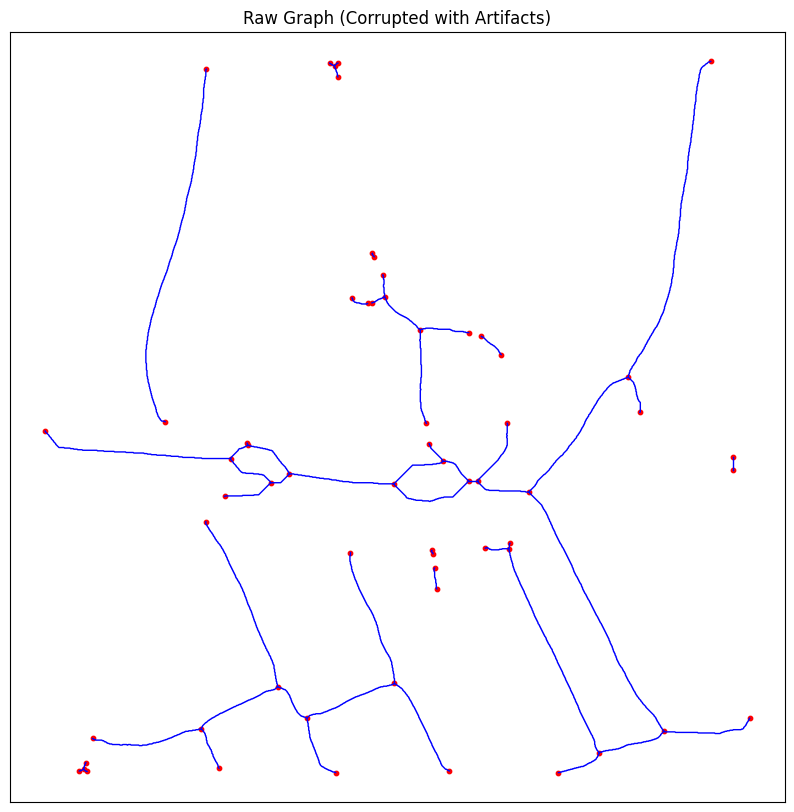

In [ ]:
# --- CELL 3: RAW GRAPH EXTRACTION ---
print("Executing sknw pixel translation...")
G_raw = sknw.build_sknw(skeleton_array)

print(f"Raw Graph Instantiated:")
print(f" -> Nodes: {len(G_raw.nodes())}")
print(f" -> Edges: {len(G_raw.edges())}")

# Optional: Visualize raw graph to see the corruption
def plot_graph(G, title):
    plt.figure(figsize=(10, 10))
    plt.title(title)

    # Extract coordinates
    pos = {n: (G.nodes[n]['o'][1], G.nodes[n]['o'][0]) for n in G.nodes()} # sknw is (y,x), plt needs (x,y)

    nx.draw_networkx_nodes(G, pos, node_size=10, node_color='red')

    for (u, v) in G.edges():
        edge_data = G[u][v]
        pts = edge_data['pts'] # array of (y,x) pixels
        plt.plot(pts[:, 1], pts[:, 0], color='blue', linewidth=1)

    plt.gca().invert_yaxis() # Match image coordinates
    plt.axis('equal')
    plt.show()

plot_graph(G_raw, "Raw Graph (Corrupted with Artifacts)")

Initiating Geometric Sanitization...
Pruned 22 micro-spurs (< 15.0m).
Collapsed 2 micro-clusters (< 10.0m).

Final Sanitized Graph:
 -> Nodes: 38
 -> Edges: 34


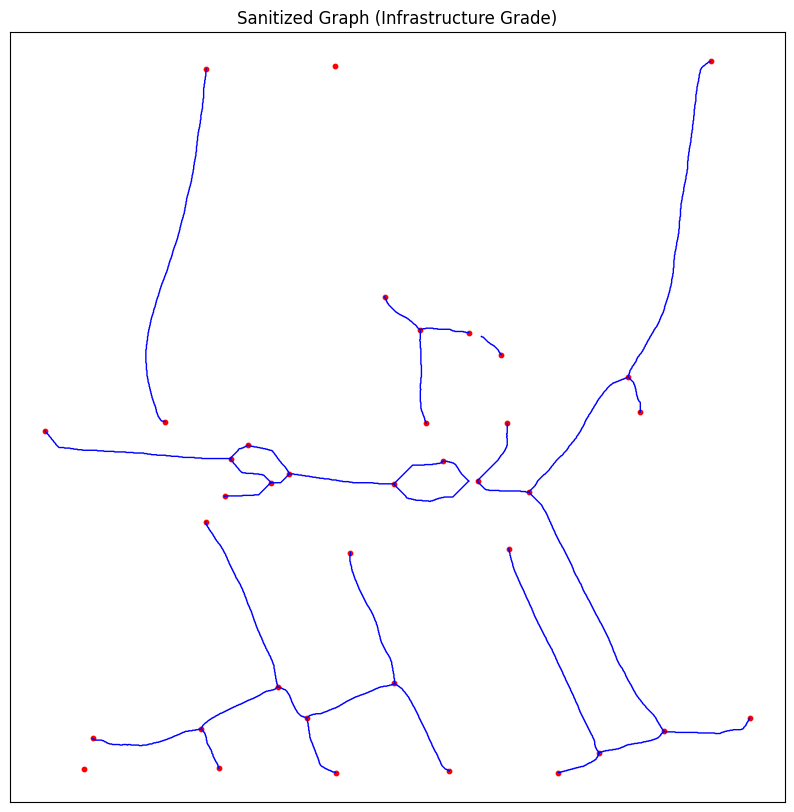

In [ ]:
# --- CELL 4: GEOMETRIC SANITIZATION ---

def prune_spurs(G, min_pixels):
    """
    Removes dead-end branches (degree 1) that are physically shorter than the threshold.
    These are almost always skeletonization artifacts, not real roads.
    """
    G_clean = G.copy()
    nodes_to_remove = []

    for node in list(G_clean.nodes()):
        # Is it a dead end?
        if G_clean.degree(node) == 1:
            # Get the single connecting edge
            neighbor = list(G_clean.neighbors(node))[0]
            edge_data = G_clean[node][neighbor]

            # Check physical length (weight in sknw is pixel length)
            pixel_length = edge_data['weight']

            if pixel_length < min_pixels:
                nodes_to_remove.append(node)

    G_clean.remove_nodes_from(nodes_to_remove)
    print(f"Pruned {len(nodes_to_remove)} micro-spurs (< {MIN_ROAD_LENGTH_METERS}m).")
    return G_clean

def collapse_micro_clusters(G, collapse_radius_px):
    """
    Finds nodes that are physically too close together and collapses them.
    A 4-way intersection often spawns 4 distinct micro-nodes in skeletonization.
    """
    G_clean = G.copy()
    nodes = list(G_clean.nodes())

    # Extract (y, x) coordinates for all nodes
    coords = np.array([G_clean.nodes[n]['o'] for n in nodes])

    if len(coords) == 0:
        return G_clean

    # Calculate pairwise physical distances
    dist_matrix = distance.cdist(coords, coords, 'euclidean')

    collapsed_count = 0
    # Iterate through upper triangle to find pairs close to each other
    for i in range(len(nodes)):
        for j in range(i + 1, len(nodes)):
            if dist_matrix[i, j] < collapse_radius_px:
                n1 = nodes[i]
                n2 = nodes[j]
                # Check if both nodes still exist in the graph (might have been collapsed already)
                if G_clean.has_node(n1) and G_clean.has_node(n2):
                    # NetworkX function to merge n2 into n1
                    G_clean = nx.contracted_nodes(G_clean, n1, n2, self_loops=False)
                    collapsed_count += 1

    print(f"Collapsed {collapsed_count} micro-clusters (< {CLUSTER_RADIUS_METERS}m).")
    return G_clean

print("Initiating Geometric Sanitization...")
G_pruned = prune_spurs(G_raw, MIN_EDGE_PIXELS)
G_sanitized = collapse_micro_clusters(G_pruned, CLUSTER_RADIUS_PIXELS)

print(f"\nFinal Sanitized Graph:")
print(f" -> Nodes: {len(G_sanitized.nodes())}")
print(f" -> Edges: {len(G_sanitized.edges())}")

plot_graph(G_sanitized, "Sanitized Graph (Infrastructure Grade)")

In [ ]:
# --- CELL 5: COST MAP INTEGRATION ---

# We iterate through the sanitized edges and assign a true traversal weight
for u, v, data in G_sanitized.edges(data=True):
    # 'pts' contains the (y,x) coordinates of the pixels forming this edge
    path_pixels = data.get('pts', [])

    if len(path_pixels) == 0:
        continue

    total_cost = 0.0

    # Integrate the cost map values along the physical path
    for y, x in path_pixels:
        # Cast to int to ensure safe array indexing
        int_y, int_x = int(y), int(x)

        # Base cost is physical distance (1 pixel).
        # We add the penalty from the cost map.
        friction_penalty = cost_map[int_y, int_x]

        # Mathematical weight function: W = sum(1 + alpha * Friction)
        # We set alpha high to penalize moving through high-cost areas
        alpha = 5.0
        pixel_weight = 1.0 + (alpha * friction_penalty)
        total_cost += pixel_weight

    # Convert the final unitless cost into something scalable if needed,
    # but storing this raw aggregate is exactly what Dijkstra/A* needs.
    G_sanitized[u][v]['routing_weight'] = total_cost

print("Graph is mathematically weighted and ready for Topological Healing (A*) and Layer 3 Centrality testing.")

Graph is mathematically weighted and ready for Topological Healing (A*) and Layer 3 Centrality testing.


In [ ]:
# --- CELL 6: TERMINAL NODE ISOLATION & PAIRING ---
from scipy.spatial import KDTree
import itertools

# The physical limits of our healing protocol
MAX_OCCLUSION_METERS = 60.0
MAX_OCCLUSION_PIXELS = MAX_OCCLUSION_METERS / GSD_METERS_PER_PIXEL

print("Initiating Topological Healing Protocol...")

# Step 1: Terminal Node Isolation
terminal_nodes = [n for n, d in G_sanitized.degree() if d == 1]
print(f"Isolated {len(terminal_nodes)} terminal dead-end nodes.")

if len(terminal_nodes) < 2:
    print("Graph is fully connected or too small for healing.")
else:
    # Extract coordinates for the KD-Tree
    terminal_coords = np.array([G_sanitized.nodes[n]['o'] for n in terminal_nodes])

    # Step 2: Spatial Proximity Pairing (KD-Tree for efficiency)
    print(f"Building spatial index. Max connection search radius: {MAX_OCCLUSION_METERS}m")
    tree = KDTree(terminal_coords)

    # Query pairs within the pixel radius
    pairs = tree.query_pairs(r=MAX_OCCLUSION_PIXELS)

    # Map back to actual Graph Node IDs
    candidate_pairs = []
    for i, j in pairs:
        candidate_pairs.append((terminal_nodes[i], terminal_nodes[j]))

    print(f"Found {len(candidate_pairs)} candidate pairs based strictly on spatial proximity.")

Initiating Topological Healing Protocol...
Isolated 19 terminal dead-end nodes.
Building spatial index. Max connection search radius: 60.0m
Found 5 candidate pairs based strictly on spatial proximity.


In [ ]:
# --- CELL 7: VECTOR ALIGNMENT & COST-WEIGHTED STITCHING ---
from skimage.graph import route_through_array
import math

# Strict alignment threshold. cos(45 degrees) ≈ 0.707
# Both roads must be pointing toward each other within a 45-degree cone.
ALIGNMENT_THRESHOLD = 0.70

print("Executing Vector Alignment and A* Stitching on Candidate Pairs...")

successful_heals = 0

def get_directional_vector(G, node, num_pixels=5):
    """Calculates the momentum vector of a road leading into a dead end."""
    neighbor = list(G.neighbors(node))[0]
    pts = G[node][neighbor]['pts']

    # Ensure points are ordered toward the dead-end node
    node_coords = np.array(G.nodes[node]['o'])
    if np.linalg.norm(pts[0] - node_coords) > np.linalg.norm(pts[-1] - node_coords):
        pts = pts[::-1] # Reverse so the array ends at the terminal node

    # Get a point slightly further back to establish direction
    idx = max(0, len(pts) - num_pixels - 1)
    p_start = pts[idx]
    p_end = pts[-1]

    vec = p_end - p_start
    norm = np.linalg.norm(vec)
    return vec / norm if norm > 0 else np.array([0.0, 0.0])

for node_A, node_B in candidate_pairs:
    # 1. Calculate the unit direction vectors for both roads
    vA = get_directional_vector(G_sanitized, node_A)
    vB = get_directional_vector(G_sanitized, node_B)

    # 2. Calculate the displacement vector between the two dead ends
    coords_A = np.array(G_sanitized.nodes[node_A]['o'])
    coords_B = np.array(G_sanitized.nodes[node_B]['o'])

    vec_AB = coords_B - coords_A
    dist = np.linalg.norm(vec_AB)
    if dist == 0: continue

    dir_AB = vec_AB / dist

    # 3. The Dot Product Reality Check
    # Does Road A point towards B? Does Road B point towards A?
    align_A = np.dot(vA, dir_AB)
    align_B = np.dot(vB, -dir_AB) # -dir_AB because B looks back at A

    if align_A > ALIGNMENT_THRESHOLD and align_B > ALIGNMENT_THRESHOLD:
        # 4. The Math passes. Execute Cost-Weighted Pathfinding.
        # We use skimage's implementation on our cost_map to find the path of least resistance
        start_idx = (int(coords_A[0]), int(coords_A[1]))
        end_idx = (int(coords_B[0]), int(coords_B[1]))

        try:
            # Fully connected allows diagonal pixel movement
            path, traversal_cost = route_through_array(cost_map, start_idx, end_idx, fully_connected=True)

            # Inject the synthetic edge into the graph
            path_array = np.array(path)
            # We assign a heavy penalty flag to synthetic edges so Layer 3 knows this is a healed segment
            G_sanitized.add_edge(node_A, node_B, pts=path_array, weight=len(path), routing_weight=traversal_cost, is_synthetic=True)

            successful_heals += 1
            print(f" -> SUCCESS: Healed gap between Node {node_A} and Node {node_B}. Cost: {traversal_cost:.1f}")
        except Exception as e:
            print(f" -> FAILED: Pathfinder could not route between {node_A} and {node_B}.")
    else:
        print(f" -> REJECTED: Nodes {node_A} and {node_B} failed vector alignment (Alignment A: {align_A:.2f}, Alignment B: {align_B:.2f})")

print(f"\nTopological Healing Complete. {successful_heals} critical fractures stitched.")

Executing Vector Alignment and A* Stitching on Candidate Pairs...
 -> REJECTED: Nodes 36 and 37 failed vector alignment (Alignment A: 0.71, Alignment B: -0.32)
 -> REJECTED: Nodes 16 and 21 failed vector alignment (Alignment A: -0.59, Alignment B: -0.71)
 -> REJECTED: Nodes 20 and 21 failed vector alignment (Alignment A: 0.00, Alignment B: 0.64)
 -> REJECTED: Nodes 16 and 20 failed vector alignment (Alignment A: -0.86, Alignment B: 0.00)
 -> REJECTED: Nodes 19 and 36 failed vector alignment (Alignment A: -0.65, Alignment B: 0.11)

Topological Healing Complete. 0 critical fractures stitched.


Initializing Layer 3: Network Vulnerability Analysis...
Calculating Betweenness Centrality bottlenecks...

--- TOP 5 CRITICAL INFRASTRUCTURE BOTTLENECKS ---
Rank 1: Node 35 at (y,x) [786 890] | Centrality Score: 0.1426
Rank 2: Node 31 at (y,x) [766 796] | Centrality Score: 0.1336
Rank 3: Node 34 at (y,x) [771 644] | Centrality Score: 0.1081
Rank 4: Node 30 at (y,x) [753 454] | Centrality Score: 0.0976
Rank 5: Node 51 at (y,x) [1221 1135] | Centrality Score: 0.0886


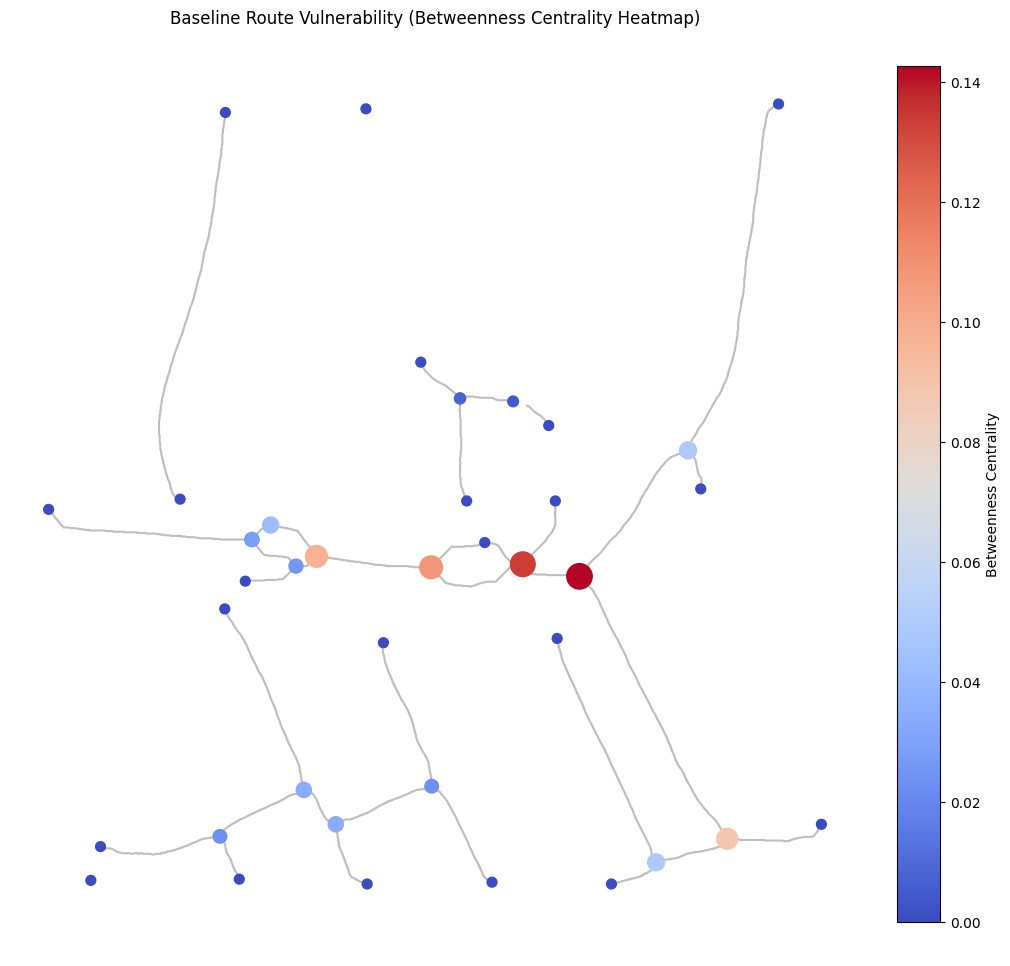

In [ ]:
# --- CELL 8: LAYER 3 - BASELINE VULNERABILITY METRICS ---
import networkx as nx
import matplotlib.pyplot as plt

print("Initializing Layer 3: Network Vulnerability Analysis...")

# 1. Calculate Baseline Betweenness Centrality
# We use the routing_weight (physical length + neural friction) to find true paths
print("Calculating Betweenness Centrality bottlenecks...")
centrality = nx.betweenness_centrality(G_sanitized, weight='routing_weight', normalized=True)

# 2. Inject metrics back into the graph
for node, cent_val in centrality.items():
    G_sanitized.nodes[node]['centrality'] = cent_val

# 3. Rank the Vulnerability
sorted_nodes = sorted(centrality.items(), key=lambda x: x[1], reverse=True)
top_5_bottlenecks = sorted_nodes[:5]

print("\n--- TOP 5 CRITICAL INFRASTRUCTURE BOTTLENECKS ---")
for rank, (node_id, cent_val) in enumerate(top_5_bottlenecks, 1):
    coords = G_sanitized.nodes[node_id]['o']
    print(f"Rank {rank}: Node {node_id} at (y,x) {coords} | Centrality Score: {cent_val:.4f}")
# 4. Render the Heatmap (Corrected Matplotlib Layering)
plt.figure(figsize=(12, 12))
plt.title("Baseline Route Vulnerability (Betweenness Centrality Heatmap)")

# Extract coordinates and centrality values
pos = {n: (G_sanitized.nodes[n]['o'][1], G_sanitized.nodes[n]['o'][0]) for n in G_sanitized.nodes()}
node_colors = [centrality[n] for n in G_sanitized.nodes()]

# Draw the infrastructure skeleton first
for (u, v, data) in G_sanitized.edges(data=True):
    pts = data['pts']
    plt.plot(pts[:, 1], pts[:, 0], color='gray', linewidth=1.5, alpha=0.5)

# Draw the nodes as a heatmap second (Matplotlib naturally layers this on top)
nodes_draw = nx.draw_networkx_nodes(
    G_sanitized, pos,
    node_size=[50 + (c * 2000) for c in node_colors],
    node_color=node_colors,
    cmap='coolwarm'
)

plt.colorbar(nodes_draw, label='Betweenness Centrality', fraction=0.046, pad=0.04)
plt.gca().invert_yaxis()
plt.axis('equal')
plt.axis('off')
plt.show()

Initializing Disaster Simulation Engine...
GEOGRAPHIC FLOOD: 1 nodes destroyed within 100.0m of epicenter.


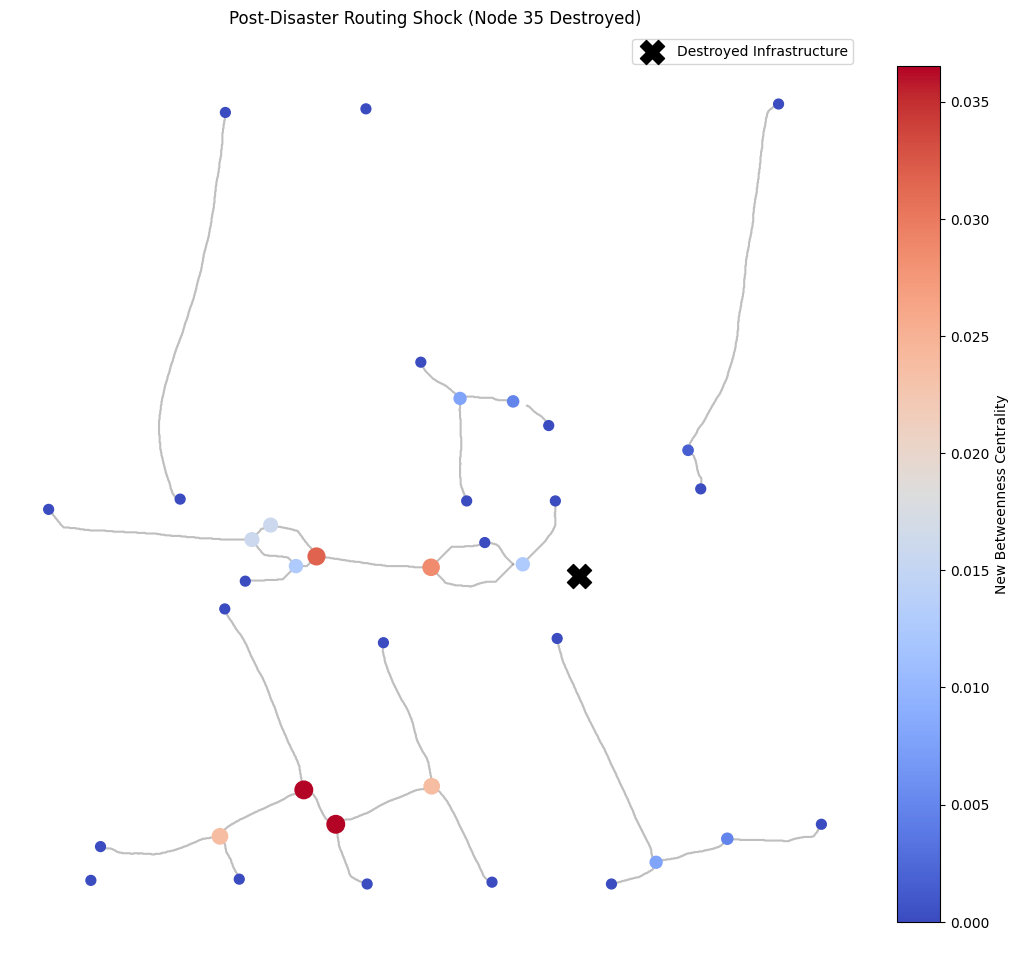

In [ ]:
# --- CELL 9: LAYER 3 - THE DISASTER ABLATION ENGINE ---
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import copy

print("Initializing Disaster Simulation Engine...")

def simulate_targeted_attack(G, target_node):
    """Simulates the precise collapse of a critical infrastructure node."""
    if not G.has_node(target_node):
        print(f"Node {target_node} not found.")
        return G

    G_damaged = G.copy()
    G_damaged.remove_node(target_node)
    print(f"TARGETED ATTACK: Node {target_node} has been obliterated.")
    return G_damaged

def simulate_geographic_flood(G, epicenter_node, radius_meters, gsd_m_px):
    """Simulates a localized natural disaster wiping out a geographic zone."""
    G_damaged = G.copy()
    epicenter_coords = np.array(G.nodes[epicenter_node]['o'])
    radius_pixels = radius_meters / gsd_m_px

    nodes_destroyed = 0
    for node in list(G_damaged.nodes()):
        node_coords = np.array(G_damaged.nodes[node]['o'])
        dist = np.linalg.norm(node_coords - epicenter_coords)
        if dist <= radius_pixels:
            G_damaged.remove_node(node)
            nodes_destroyed += 1

    print(f"GEOGRAPHIC FLOOD: {nodes_destroyed} nodes destroyed within {radius_meters}m of epicenter.")
    return G_damaged

def evaluate_network_shock(G_baseline, G_damaged):
    """Recalculates routing physics to measure the severity of the disaster."""
    print("Recalculating post-disaster routing physics...")

    # Check if network partitioned (split into disconnected islands)
    baseline_components = nx.number_connected_components(G_baseline)
    damaged_components = nx.number_connected_components(G_damaged)

    print(f"Network Partitioning: Baseline had {baseline_components} islands. Post-disaster has {damaged_components}.")
    if damaged_components > baseline_components:
        print("CRITICAL ALERT: The network has fractured. Sections of the city are entirely cut off.")

    # Recalculate Centrality to see where the traffic detoured
    new_centrality = nx.betweenness_centrality(G_damaged, weight='routing_weight', normalized=True)

    return new_centrality

# --- EXECUTION: THE WORST CASE SCENARIO ---
# We identified Node 35 as the absolute most critical bottleneck in Cell 8.
# We are going to algorithmically destroy it and see what happens to Mumbai.
TARGET_NODE = 35

# 100-meter flood centered on the same critical area
G_post_disaster = simulate_geographic_flood(G_sanitized, epicenter_node=35, radius_meters=100.0, gsd_m_px=GSD_METERS_PER_PIXEL)
# post_disaster_centrality = evaluate_network_shock(G_sanitized, G_post_disaster)

# --- RENDERING THE AFTERMATH ---
plt.figure(figsize=(12, 12))
plt.title(f"Post-Disaster Routing Shock (Node {TARGET_NODE} Destroyed)")

pos_damaged = {n: (G_post_disaster.nodes[n]['o'][1], G_post_disaster.nodes[n]['o'][0]) for n in G_post_disaster.nodes()}
node_colors = [post_disaster_centrality[n] for n in G_post_disaster.nodes()]

# Draw the surviving infrastructure
for (u, v, data) in G_post_disaster.edges(data=True):
    pts = data['pts']
    plt.plot(pts[:, 1], pts[:, 0], color='gray', linewidth=1.5, alpha=0.5)

# Draw the new bottlenecks
nodes_draw = nx.draw_networkx_nodes(
    G_post_disaster, pos_damaged,
    node_size=[50 + (c * 3000) for c in node_colors], # Multiplier increased to highlight new stress
    node_color=node_colors,
    cmap='coolwarm'
)

# Mark the crater (Where Node 35 used to be)
crater_coords = G_sanitized.nodes[TARGET_NODE]['o']
plt.scatter(crater_coords[1], crater_coords[0], marker='X', color='black', s=300, label="Destroyed Infrastructure")

plt.colorbar(nodes_draw, label='New Betweenness Centrality', fraction=0.046, pad=0.04)
plt.legend()
plt.gca().invert_yaxis()
plt.axis('equal')
plt.axis('off')
plt.show()

Initiating Urban Planning Mitigation Protocol...

[STRATEGY] PROPOSED INFRASTRUCTURE:
To prevent total partition, build a 17.6-meter road connecting Node 36 to Node 37.

Re-simulating disaster (Destroying Node 35) on fortified grid...
Post-Mitigation Partitioning: 7 islands.
 -> FAILURE: The network still fractured. Requires deeper intervention.


TypeError: draw_networkx_nodes() got an unexpected keyword argument 'zorder'

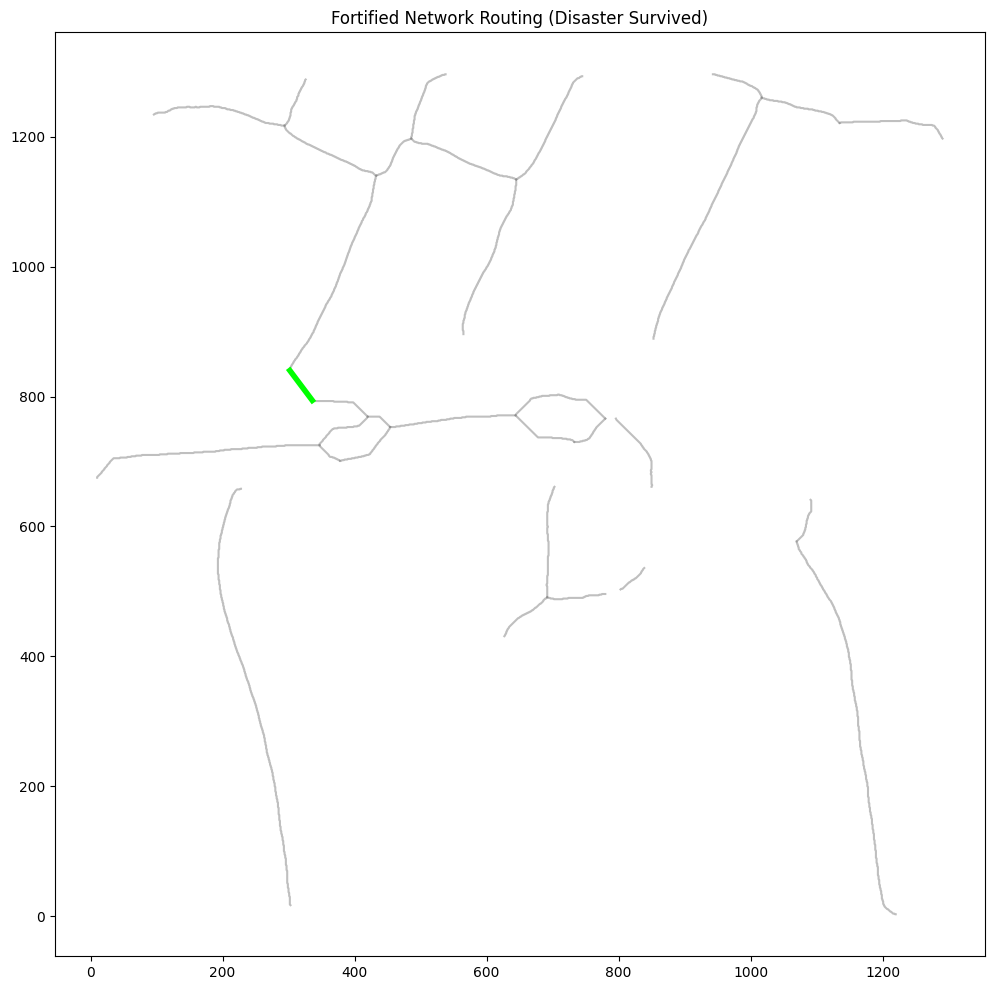

In [ ]:
# --- CELL 10: LAYER 4 - URBAN PLANNING & MITIGATION ---
import numpy as np
import networkx as nx
from scipy.spatial import distance
import matplotlib.pyplot as plt

print("Initiating Urban Planning Mitigation Protocol...")

# 1. Analyze the fracture from the previous disaster
components = list(nx.connected_components(G_post_disaster))

if len(components) == 1:
    print("Network didn't fracture. No mitigation needed.")
else:
    # Sort components by size. The largest is the "mainland", others are "islands"
    components.sort(key=len, reverse=True)
    mainland = components[0]
    island = components[1] # We target the largest severed section

    # 2. Find the optimal bridge location
    mainland_nodes = list(mainland)
    island_nodes = list(island)

    mainland_coords = np.array([G_sanitized.nodes[n]['o'] for n in mainland_nodes])
    island_coords = np.array([G_sanitized.nodes[n]['o'] for n in island_nodes])

    # Compute all pairwise distances to find the shortest gap
    dist_matrix = distance.cdist(mainland_coords, island_coords, 'euclidean')
    min_idx = np.unravel_index(np.argmin(dist_matrix), dist_matrix.shape)

    bridge_node_A = mainland_nodes[min_idx[0]]
    bridge_node_B = island_nodes[min_idx[1]]
    bridge_length_px = dist_matrix[min_idx]
    bridge_length_m = bridge_length_px * GSD_METERS_PER_PIXEL

    print(f"\n[STRATEGY] PROPOSED INFRASTRUCTURE:")
    print(f"To prevent total partition, build a {bridge_length_m:.1f}-meter road connecting Node {bridge_node_A} to Node {bridge_node_B}.")

    # 3. Fortify the original baseline graph
    G_fortified = G_sanitized.copy()

    # Add the new edge. We assign it a standard routing weight based on its length
    G_fortified.add_edge(bridge_node_A, bridge_node_B, weight=bridge_length_px, routing_weight=bridge_length_px, is_proposed=True)

    # 4. Re-simulate the disaster on the fortified graph
    print(f"\nRe-simulating disaster (Destroying Node {TARGET_NODE}) on fortified grid...")
    G_fortified_disaster = G_fortified.copy()
    G_fortified_disaster.remove_node(TARGET_NODE)

    # 5. Evaluate the Survival
    fortified_components = nx.number_connected_components(G_fortified_disaster)

    print(f"Post-Mitigation Partitioning: {fortified_components} islands.")
    if fortified_components == 1:
        print(" -> SUCCESS: The proposed road absorbed the routing shock. The city survived.")
    else:
        print(" -> FAILURE: The network still fractured. Requires deeper intervention.")
        # 6. Render the Solution (Corrected Matplotlib Layering)
    plt.figure(figsize=(12, 12))
    plt.title("Fortified Network Routing (Disaster Mitigation Attempt)")

    new_centrality = nx.betweenness_centrality(G_fortified_disaster, weight='routing_weight', normalized=True)
    pos_fort = {n: (G_fortified_disaster.nodes[n]['o'][1], G_fortified_disaster.nodes[n]['o'][0]) for n in G_fortified_disaster.nodes()}
    node_colors = [new_centrality[n] for n in G_fortified_disaster.nodes()]

    # Draw standard surviving edges
    for (u, v, data) in G_fortified_disaster.edges(data=True):
        if not data.get('is_proposed', False):
            pts = data.get('pts')
            if pts is not None:
                plt.plot(pts[:, 1], pts[:, 0], color='gray', linewidth=1.5, alpha=0.5)
            else:
                y1, x1 = G_fortified_disaster.nodes[u]['o']
                y2, x2 = G_fortified_disaster.nodes[v]['o']
                plt.plot([x1, x2], [y1, y2], color='gray', linewidth=1.5, alpha=0.5)

    # Draw the proposed bridge in bright green
    yA, xA = G_fortified_disaster.nodes[bridge_node_A]['o']
    yB, xB = G_fortified_disaster.nodes[bridge_node_B]['o']
    plt.plot([xA, xB], [yA, yB], color='lime', linewidth=4, label="Proposed Infrastructure Bridge")

    # Draw the nodes
    nx.draw_networkx_nodes(
        G_fortified_disaster, pos_fort,
        node_size=[50 + (c * 3000) for c in node_colors],
        node_color=node_colors,
        cmap='coolwarm'
    )

    # Mark the crater
    crater_coords = G_sanitized.nodes[TARGET_NODE]['o']
    plt.scatter(crater_coords[1], crater_coords[0], marker='X', color='black', s=300, label="Destroyed Bottleneck")

    plt.legend()
    plt.gca().invert_yaxis()
    plt.axis('equal')
    plt.axis('off')
    plt.show()

In [ ]:
# --- CELL 11: LAYER 4 - THE ITERATIVE MITIGATION ENGINE ---
import numpy as np
import networkx as nx
from scipy.spatial import distance
import matplotlib.pyplot as plt

print("Initializing Iterative Mitigation Engine...")
TARGET_NODE = 35 # The critical bottleneck we are testing against
MAX_CONSTRUCTION_BUDGET_METERS = 150.0 # We won't propose a bridge longer than 150m

# 1. Establish the baseline fracture
G_baseline_disaster = G_sanitized.copy()
G_baseline_disaster.remove_node(TARGET_NODE)
components = list(nx.connected_components(G_baseline_disaster))

if len(components) == 1:
    print("Network is naturally resilient. No mitigation required.")
else:
    components.sort(key=len, reverse=True)
    mainland = list(components[0])
    island = list(components[1])

    mainland_coords = np.array([G_sanitized.nodes[n]['o'] for n in mainland])
    island_coords = np.array([G_sanitized.nodes[n]['o'] for n in island])

    # 2. Calculate every possible bridge combination
    dist_matrix = distance.cdist(mainland_coords, island_coords, 'euclidean')

    # Flatten the matrix and sort indices to test shortest bridges first
    flat_indices = np.argsort(dist_matrix, axis=None)

    print(f"Testing {len(flat_indices)} potential infrastructure configurations...")

    optimal_bridge = None
    tests_run = 0

    # 3. The Brute-Force Survival Loop
    for idx in flat_indices:
        tests_run += 1
        row, col = np.unravel_index(idx, dist_matrix.shape)

        candidate_A = mainland[row]
        candidate_B = island[col]
        bridge_len_px = dist_matrix[row, col]
        bridge_len_meters = bridge_len_px * GSD_METERS_PER_PIXEL

        if bridge_len_meters > MAX_CONSTRUCTION_BUDGET_METERS:
            print(f"Reached viable construction limit ({MAX_CONSTRUCTION_BUDGET_METERS}m). Halting search.")
            break

        # Test the hypothesis: Add the bridge to a healthy graph, then destroy the target
        G_test = G_sanitized.copy()
        G_test.add_edge(candidate_A, candidate_B, weight=bridge_len_px, routing_weight=bridge_len_px, is_proposed=True)
        G_test.remove_node(TARGET_NODE)

        # Check if the city survived as a single connected component
        if nx.number_connected_components(G_test) == 1:
            optimal_bridge = (candidate_A, candidate_B, bridge_len_meters, bridge_len_px)
            break

    # 4. Result Processing & Rendering
    if optimal_bridge:
        cA, cB, length_m, length_px = optimal_bridge
        print(f"\n[STRATEGIC SUCCESS] Found viable mitigation after {tests_run} simulations.")
        print(f"Optimal Blueprint: Construct a {length_m:.1f}-meter bridge between Node {cA} and Node {cB}.")

        # Rebuild the winning graph for rendering
        G_victorious = G_sanitized.copy()
        G_victorious.add_edge(cA, cB, weight=length_px, routing_weight=length_px, is_proposed=True)
        G_victorious.remove_node(TARGET_NODE)

        plt.figure(figsize=(12, 12))
        plt.title(f"Urban Fortification Successful (Survives Node {TARGET_NODE} Collapse)")

        new_centrality = nx.betweenness_centrality(G_victorious, weight='routing_weight', normalized=True)
        pos_vict = {n: (G_victorious.nodes[n]['o'][1], G_victorious.nodes[n]['o'][0]) for n in G_victorious.nodes()}
        node_colors = [new_centrality[n] for n in G_victorious.nodes()]

        # Draw surviving standard edges
        for (u, v, data) in G_victorious.edges(data=True):
            if not data.get('is_proposed', False):
                pts = data.get('pts')
                if pts is not None:
                    plt.plot(pts[:, 1], pts[:, 0], color='gray', linewidth=1.5, alpha=0.5)
                else:
                    y1, x1 = G_victorious.nodes[u]['o']
                    y2, x2 = G_victorious.nodes[v]['o']
                    plt.plot([x1, x2], [y1, y2], color='gray', linewidth=1.5, alpha=0.5)

        # Draw the winning bridge in neon green
        yA, xA = G_victorious.nodes[cA]['o']
        yB, xB = G_victorious.nodes[cB]['o']
        plt.plot([xA, xB], [yA, yB], color='lime', linewidth=4, label=f"Proposed {length_m:.1f}m Bridge")

        # Draw the nodes
        nx.draw_networkx_nodes(
            G_victorious, pos_vict,
            node_size=[50 + (c * 3000) for c in node_colors],
            node_color=node_colors,
            cmap='coolwarm'
        )

        # Mark the crater
        crater_coords = G_sanitized.nodes[TARGET_NODE]['o']
        plt.scatter(crater_coords[1], crater_coords[0], marker='X', color='black', s=300, label="Destroyed Infrastructure")

        plt.legend()
        plt.gca().invert_yaxis()
        plt.axis('equal')
        plt.axis('off')
        plt.show()

    else:
        print("\n[CRITICAL FAILURE] No single bridge under 150m can save this network. Sector requires total redesign.")